# 1. BlendPATH Usage Walkthrough

## 1.1 Installing and Importing BlendPATH

> **Note:** This walkthrough uses a beta version of BlendPATH that is not yet available on PyPI. Install it from the source files by running the following command in the BlendPATH folder:

```bash
pip install .
```

Once the release is published, BlendPATH can also be installed from PyPI with `pip install BlendPATH`.

After BlendPATH is installed, import the package in Python using:

In [1]:
from pathlib import Path  # handles file paths on any operating system

import numpy as np  # numerical library, used here for np.inf (infinity) in plot ranges
import pandas as pd  # table library, used here to read the Excel result files
import BlendPATH

## 1.2 BlendPATH Networks

Networks are a core component of BlendPATH. A network stores the pipeline-system structure and equipment, including nodes, pipes, supply nodes, demand nodes, compressors, and regulators. Networks are most commonly provided to BlendPATH through Excel network files.

Network files contain the physical network data and operating inputs. The sheets in `network_design.xlsx` are organized as:

- `PIPES`
- `NODES`
- `COMPRESSORS`
- `REGULATORS`
- `SUPPLY`
- `DEMAND`
- `COMPOSITION`

For this walkthrough, import the file as a `BlendPATH_network` using:

In [2]:
network_file_path = Path("distribution_example/network_design.xlsx")
bp_network = BlendPATH.BlendPATH_network.import_from_file(name=network_file_path, scenario_type="distribution")

Let's inspect the imported network.

In [3]:
print(f"Number of pipes: {len(bp_network.pipes)}")
print(f"Number of nodes: {len(bp_network.nodes)}")
print(f"Number of regulators: {len(bp_network.regulators)}")
print(f"Total pipe length: {sum([pipe.length_km for pipe in bp_network.pipes.values()]):.2f} km")
print(f"Total network demand: {bp_network.capacity_MMBTU_day:.2f} MMBTU/day")

Number of pipes: 19304
Number of nodes: 19148
Number of regulators: 18
Total pipe length: 188.29 km
Total network demand: 889.98 MMBTU/day


Now that the network is imported, we can solve the network hydraulics. This may take 30 seconds.

In [4]:
bp_network.solve(c_relax=2.0)

The `solve()` method evaluates network pressure, flow, and velocity while satisfying the supply and demand boundary conditions.

The results can be visualized using `plot()`. By default, the average pipe velocity is shown.

**Legend**

- 🟠 Supply nodes
- <span style="color: green;">&#9664;</span> Regulators
- ⚫ Demand nodes

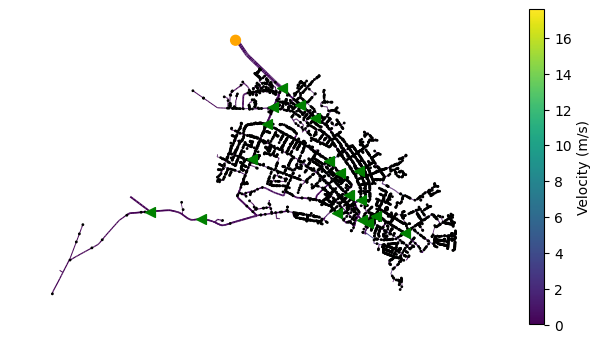

In [5]:
bp_network.plot()

The network has a higher-pressure part upstream of the regulators and a lower-pressure part downstream. We can plot the two separately by splitting on the average pipe pressure at 1.0 MPa.

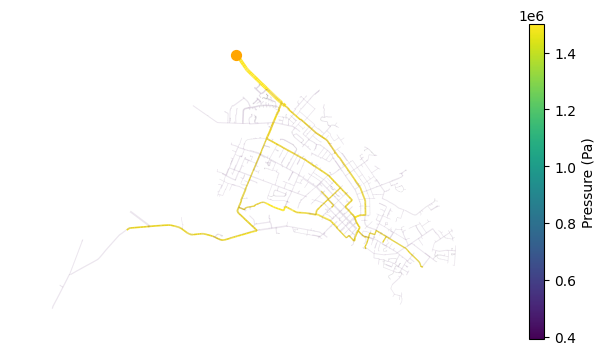

In [6]:
p_split = 1e6

# property_range=(p_split, np.inf) shows only the pipes above 1.0 MPa
bp_network.plot(pipe_property="p_avg", property_range=(p_split, np.inf), show_demands=False, show_regulators=False)

And the pipes below 1.0 MPa:

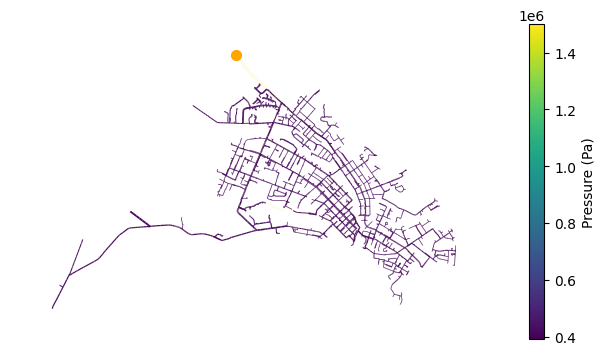

In [7]:
bp_network.plot(pipe_property="p_avg", property_range=(0, p_split), show_demands=False, show_regulators=False)

### 1.2.1 Supply Pressure and Regulator Modes

After the solve, each regulator is in one of three modes: `control` (it holds its outlet setpoint), `open` (the inlet pressure is below the setpoint, so the outlet follows the inlet), or `closed` (no forward flow). At the 1.5 MPa-g supply pressure, all regulators are in control:

In [8]:
{name: str(regulator.mode) for name, regulator in bp_network.regulators.items()}

{'REG_00287': 'control',
 'REG_00486': 'control',
 'REG_02314': 'control',
 'REG_04856': 'control',
 'REG_05735': 'control',
 'REG_13041': 'control',
 'REG_11963': 'control',
 'REG_11027': 'control',
 'REG_11297': 'control',
 'REG_13682': 'control',
 'REG_17296': 'control',
 'REG_14289': 'control',
 'REG_03855': 'control',
 'REG_07687': 'control',
 'REG_08808': 'control',
 'REG_10118': 'control',
 'REG_12770': 'control',
 'REG_12917': 'control'}

If we lower the supply pressure to 0.45 MPa-g, which is close to the regulator setpoint, some regulators can no longer hold their setpoint and switch to open. We import the network again so that this case does not change `bp_network`.

In [9]:
low_supply_network = BlendPATH.BlendPATH_network.import_from_file(name=network_file_path, scenario_type="distribution")

# The supply pressure is normally set in the SUPPLY sheet of the network file.
# Here we change it directly to 0.45 MPa-g for every supply node.
for supply in low_supply_network.supply_nodes.values():
    supply.pressure_mpa = 0.45
    supply.node.pressure = 0.45e6
low_supply_network.solve(c_relax=2.0)

{name: str(regulator.mode) for name, regulator in low_supply_network.regulators.items() if regulator.mode != "control"}

{'REG_02314': 'open', 'REG_17296': 'open', 'REG_14289': 'open'}

### 1.2.2 Hydrogen Blending

The network can also be solved with a hydrogen blend using `blendH2()`. The energy demand stays the same, so the mass flow changes with the heating value of the blend. Here we solve the network with 100% hydrogen and check the maximum pipe velocity.

In [10]:
h2_network = BlendPATH.BlendPATH_network.import_from_file(name=network_file_path, scenario_type="distribution")
h2_network.blendH2(1.0)
h2_network.solve(c_relax=2.0)

print(f"Maximum velocity with natural gas: {max(pipe.v_max for pipe in bp_network.pipes.values()):.1f} m/s")
print(f"Maximum velocity with 100% hydrogen: {max(pipe.v_max for pipe in h2_network.pipes.values()):.1f} m/s")

Maximum velocity with natural gas: 17.6 m/s
Maximum velocity with 100% hydrogen: 55.8 m/s


The velocity goes up with hydrogen, because more volume has to flow to deliver the same energy. The next section shows how BlendPATH modifies the network to bring the velocities down.

## 1.3 BlendPATH Scenarios

BlendPATH scenarios are used for pipeline assessment and network modification. A scenario is created from a case-study directory, which contains the network file. Here we use `design_option=0.32` and a blend of 100% hydrogen. By default, BlendPATH uses a design factor of 0.4 for steel pipes and 0.32 for plastic pipes.

In [11]:
bp_scenario = BlendPATH.BlendPATH_scenario(casestudy_name="distribution_example", scenario_type="distribution", design_option=0.32, blend=1.0)

The scenario has its own BlendPATH network. Let's solve and plot it before running any modification.

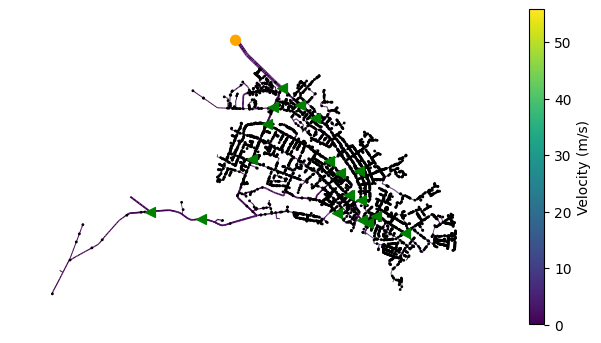

In [12]:
bp_scenario.network.solve(c_relax=2.0)
bp_scenario.network.plot()

For distribution scenarios, a maximum velocity can be specified in meters per second. We use 20 m/s here. This is the nominal maximum velocity in UK gas distribution standards where dust or debris may be present, as summarized in the SGN and DNV project [*Velocity Design with Hydrogen* (2022)](https://smarter.energynetworks.org/projects/10027185/). We then plot the pipes that are above it.

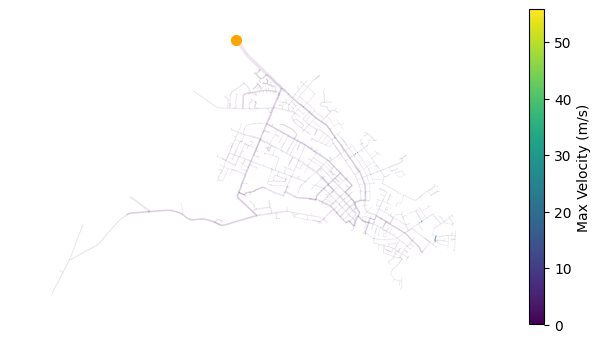

In [13]:
bp_scenario.max_velocity_distribution = 20

# property_range shows only the pipes above the velocity limit (np.inf: no upper bound)
bp_scenario.network.plot(pipe_property="v_max", property_range=(bp_scenario.max_velocity_distribution, np.inf), show_demands=False, show_regulators=False)

These pipes are short and spread over the network, so they are hard to see on the map. We can list them instead.

In [14]:
high_v_pipes = {
    pipe.name: pipe.v_max
    for pipe in bp_scenario.network.pipes.values()
    if pipe.v_max > bp_scenario.max_velocity_distribution
}

print(f"Number of pipes above the limit: {len(high_v_pipes)}")
high_v_pipes

Number of pipes above the limit: 77


{'pipe_4118_4120': np.float64(22.49251552331323),
 'pipe_7923_8000': np.float64(20.230233706705068),
 'pipe_4641_4725': np.float64(20.845638089851494),
 'pipe_7686_19106': np.float64(27.36496963747067),
 'pipe_14080_14114': np.float64(42.70853673503449),
 'pipe_14562_14569': np.float64(44.5120601483227),
 'pipe_14569_14594': np.float64(42.266874764142024),
 'pipe_7530_7549': np.float64(22.510822520842076),
 'pipe_7549_7556': np.float64(20.382724205894828),
 'pipe_14496_14500': np.float64(22.451699887831047),
 'pipe_14492_14496': np.float64(33.3955924082653),
 'pipe_8450_8453': np.float64(21.632022656687074),
 'pipe_8453_8458': np.float64(22.42689576274009),
 'pipe_12771_19195': np.float64(55.822772901887156),
 'pipe_12771_12789': np.float64(41.59714239750393),
 'pipe_13436_13437': np.float64(32.42061134199362),
 'pipe_13434_13437': np.float64(32.5728655051698),
 'pipe_13872_13903': np.float64(41.41653044242413),
 'pipe_17788_17877': np.float64(35.56202651765111),
 'pipe_17877_17886': n

### 1.3.1 Direct Replacement

The direct-replacement method replaces the high-velocity pipes with larger pipe sizes. This calculation may take a few minutes.

In [15]:
dr_lcot = float(bp_scenario.run_mod(mod_type="DR"))
dr_network = bp_scenario.new_network

After direct replacement, the modified network is available as `dr_network`. We can plot its maximum velocities and check the new velocity of the pipes that were above the limit before.

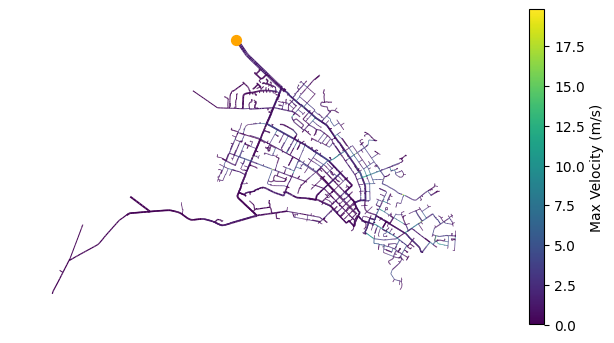

Number of pipes above the limit: 0


{'pipe_4118_4120': np.float64(14.420375902691982),
 'pipe_7923_8000': np.float64(16.313150623246884),
 'pipe_4641_4725': np.float64(16.08929858034316),
 'pipe_7686_19106': np.float64(13.81722076695889),
 'pipe_14080_14114': np.float64(16.62894238639583),
 'pipe_14562_14569': np.float64(14.239530854527668),
 'pipe_14569_14594': np.float64(13.363228079505133),
 'pipe_7530_7549': np.float64(15.555818453959793),
 'pipe_7549_7556': np.float64(14.223835464309229),
 'pipe_14496_14500': np.float64(15.806208938493056),
 'pipe_14492_14496': np.float64(15.15354455650169),
 'pipe_8450_8453': np.float64(16.29603327827367),
 'pipe_8453_8458': np.float64(16.858971088958423),
 'pipe_12771_19195': np.float64(15.63229080464075),
 'pipe_12771_12789': np.float64(19.812758571536612),
 'pipe_13436_13437': np.float64(11.458902061387962),
 'pipe_13434_13437': np.float64(11.374768602673084),
 'pipe_13872_13903': np.float64(13.863800010580055),
 'pipe_17788_17877': np.float64(17.962770784179018),
 'pipe_17877_1

In [16]:
dr_network.plot(pipe_property="v_max", show_demands=False, show_regulators=False)

n_above = sum(pipe.v_max > bp_scenario.max_velocity_distribution for pipe in dr_network.pipes.values())
print(f"Number of pipes above the limit: {n_above}")

{pipe_name: dr_network.pipes[pipe_name].v_max for pipe_name in high_v_pipes}

Direct replacement does not add any pipe to the network, so the total length is unchanged.

In [17]:
print(f"Original network length = {sum([pipe.length_km for pipe in bp_scenario.network.pipes.values()]):.2f} km")
print(f"Modified network length = {sum([pipe.length_km for pipe in dr_network.pipes.values()]):.2f} km")

Original network length = 188.29 km
Modified network length = 188.29 km


During the `run_mod` process, two files are produced:
 - `distribution_example/out/NetworkFiles/DR_1.0_0.32_network_design.xlsx`
 - `distribution_example/out/ResultFiles/DR_1.0_0.32.xlsx`

The `DR_1.0_0.32_network_design.xlsx` file is the network file of the modified network. The `DR_1.0_0.32.xlsx` file is a summary file of the modification analysis. It includes the economics and, for distribution networks, the regulator modes of the modified network in the `Regulators` sheet.

### 1.3.2 Parallel Loop

The parallel-loop method keeps the existing pipes and adds a parallel pipe along the high-velocity sections. The extra flow area brings the velocity down without replacing the original pipe.

In [18]:
pl_lcot = float(bp_scenario.run_mod(mod_type="PL"))
pl_network = bp_scenario.new_network

The added pipes can be found by comparing the pipe names of the original and modified networks. Their maximum velocities are:

In [19]:
# pipe names in the modified network that are not in the original network
added_PL_pipes = set(pl_network.pipes) - set(bp_scenario.network.pipes)

{pipe_name: pl_network.pipes[pipe_name].v_max for pipe_name in added_PL_pipes}

{'pipe_18273_18278_mod_looped': np.float64(12.024528847726748),
 'pipe_12655_12658_mod_looped': np.float64(12.558183415853867),
 'pipe_18252_18253_mod_looped': np.float64(12.430134736581298),
 'pipe_18253_18254_mod_looped': np.float64(12.432335038428649),
 'pipe_14080_14114_mod_looped': np.float64(18.763850583538428),
 'pipe_18250_18254_mod_looped': np.float64(12.434735482181086),
 'pipe_18263_18269_mod_looped': np.float64(12.265811689382565),
 'pipe_18262_18264_mod_looped': np.float64(12.41072072162571),
 'pipe_7923_8000_mod_looped': np.float64(14.811430553679331),
 'pipe_12396_12405_mod_looped': np.float64(12.709670202817396),
 'pipe_18272_18276_mod_looped': np.float64(12.504367366735451),
 'pipe_18228_18244_mod_looped': np.float64(12.442192289545),
 'pipe_18271_18272_mod_looped': np.float64(12.510254405462808),
 'pipe_18270_18273_mod_looped': np.float64(12.153487091002216),
 'pipe_18231_18232_mod_looped': np.float64(12.317183244809623),
 'pipe_18257_18263_mod_looped': np.float64(12.

The total length of added parallel pipe can also be calculated.

In [20]:
print(f"Added pipe length = {sum([pl_network.pipes[pipe_name].length_km for pipe_name in added_PL_pipes]):.3f} km")

Added pipe length = 0.461 km


## 1.4 Economics

The `run_mod()` method returns the levelized cost of transport (LCOT) of the modification in $/MMBTU. This is the incremental cost of pipeline transport for the selected technical and financial assumptions. It does not include the cost of producing hydrogen. The detailed economic outputs are written to the Excel file under `out/ResultFiles`.

In [21]:
print(f"Direct replacement LCOT = {dr_lcot:.4f} $/MMBTU")
print(f"Parallel loop LCOT = {pl_lcot:.4f} $/MMBTU")

Direct replacement LCOT = 0.2054 $/MMBTU
Parallel loop LCOT = 0.2061 $/MMBTU


Both methods bring the maximum velocity below 20 m/s, and the LCOT is very similar for the two.

## 1.5 Per-Pipe Design Factor and Velocity Limit

The scenario above uses the default design factors (0.4 for steel, 0.32 for plastic pipes) and the same maximum velocity (20 m/s) for all pipes. Both can also be set for individual pipes, either with the `design_factor` and `velocity_limit` columns in the `PIPES` sheet of the network file or directly on the pipes of a scenario. Pipes without a value use the scenario values.

### 1.5.1 Design Factor

As an example, we lower the design factor of the first 50 plastic pipes in the network from 0.32 to 0.2 and run the direct replacement again. The `filename_suffix` keeps the result files of this case separate.

In [22]:
df_scenario = BlendPATH.BlendPATH_scenario(casestudy_name="distribution_example", scenario_type="distribution", design_option=0.32, blend=1.0, filename_suffix="_low_DF")
df_scenario.max_velocity_distribution = 20

# names of the first 50 plastic pipes
df_pipes = [pipe.name for pipe in df_scenario.network.pipes.values() if pipe.material == "polymer"][:50]

for pipe_name in df_pipes:
    df_scenario.network.pipes[pipe_name].design_factor = 0.2

# reassess the pipe design pressures with the new design factors
df_scenario.network.pipe_assessment(df_scenario.design_params.asme, design_option=df_scenario.design_option)

df_lcot = float(df_scenario.run_mod(mod_type="DR"))

print(f"Direct replacement LCOT, default design factors = {dr_lcot:.4f} $/MMBTU")
print(f"Direct replacement LCOT, design factor 0.2 for 50 plastic pipes = {df_lcot:.4f} $/MMBTU")

Direct replacement LCOT, default design factors = 0.2054 $/MMBTU
Direct replacement LCOT, design factor 0.2 for 50 plastic pipes = 0.2761 $/MMBTU


Lowering the design factor reduces the design pressure of the selected plastic pipes. Pipes whose design pressure falls below the maximum pressure of their pipe segment are replaced, which adds to the new pipe cost.

### 1.5.2 Velocity Limit

Next, we set a velocity limit of 15 m/s for the pipes that are between 15 and 20 m/s at 100% hydrogen. These pipes are below the 20 m/s limit of the scenario, so they were not changed in the direct replacement above.

In [23]:
vl_scenario = BlendPATH.BlendPATH_scenario(casestudy_name="distribution_example", scenario_type="distribution", design_option=0.32, blend=1.0, filename_suffix="_low_velocity")
vl_scenario.max_velocity_distribution = 20
vl_scenario.network.solve(c_relax=2.0)

# names of the pipes between 15 and 20 m/s
vl_pipes = [pipe.name for pipe in vl_scenario.network.pipes.values() if 15 < pipe.v_max <= 20]

for pipe_name in vl_pipes:
    vl_scenario.network.pipes[pipe_name].velocity_limit = 15

vl_lcot = float(vl_scenario.run_mod(mod_type="DR"))
vl_network = vl_scenario.new_network

print(f"Number of pipes with a 15 m/s limit: {len(vl_pipes)}")
print(f"Maximum velocity in these pipes after direct replacement: {max(vl_network.pipes[pipe_name].v_max for pipe_name in vl_pipes):.1f} m/s")
print(f"Direct replacement LCOT, 20 m/s for all pipes = {dr_lcot:.4f} $/MMBTU")
print(f"Direct replacement LCOT, 15 m/s for selected pipes = {vl_lcot:.4f} $/MMBTU")

Number of pipes with a 15 m/s limit: 58
Maximum velocity in these pipes after direct replacement: 14.8 m/s
Direct replacement LCOT, 20 m/s for all pipes = 0.2054 $/MMBTU
Direct replacement LCOT, 15 m/s for selected pipes = 0.2643 $/MMBTU


The cost breakdown of the three cases is in the `Capital` sheet of the result files:

In [24]:
result_files = "distribution_example/out/ResultFiles/"

# read the Capital sheet of each result file and show them side by side
pd.concat(
    {
        "Scenario values": pd.read_excel(result_files + "DR_1.0_0.32.xlsx", sheet_name="Capital", index_col="Item")["Value ($)"],
        "DF 0.2 for 50 plastic pipes": pd.read_excel(result_files + "DR_1.0_0.32_low_DF.xlsx", sheet_name="Capital", index_col="Item")["Value ($)"],
        "15 m/s for selected pipes": pd.read_excel(result_files + "DR_1.0_0.32_low_velocity.xlsx", sheet_name="Capital", index_col="Item")["Value ($)"],
    },
    axis=1,
).loc[lambda table: (table != 0).any(axis=1)].round(0)  # hide items that are zero in all cases

,Scenario values,DF 0.2 for 50 plastic pipes,15 m/s for selected pipes
Item,,,
New pipe CapEx,149022.0,301447.0,275975.0
Valve replacement CapEx,28350.0,28350.0,28350.0
Gas pressure regulation and metering station refurbishment,135000.0,135000.0,135000.0
Regulator at supply node,120000.0,120000.0,120000.0
Meter set assembly,1157045.0,1157045.0,1157045.0


Note that these results are screening-level estimates. A converged hydraulic solution does not mean that the existing pipes, regulators, meters, or end-use equipment are suitable for hydrogen service.